In [53]:
from pylab import rcParams
    
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
rcParams['figure.figsize'] = 10, 10

X = np.loadtxt('Data_file_awa/predicate-matrix-continuous.txt')
names = [l.split()[1].replace('+',' ') for l in open('Data_file_awa/classes.txt')]


In [54]:
print(X.shape, len(names))

(50, 85) 50


In [55]:
scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)
X_scaled = X

In [56]:
pca = PCA(n_components=2)
Z_pa = pca.fit_transform(X_scaled)
x = Z_pa[:,0]
y = Z_pa[:,1]

print(x.shape, y.shape)


(50,) (50,)


In [57]:
def plot_embedding(Z, title):
    plt.figure(figsize=(10, 10))
    x = Z[:,0]
    y = Z[:,1]
    plt.scatter(x, y, alpha=0.7) 
    for (x,y),n in zip(Z,names): plt.annotate(n,(x,y),fontsize=9)
    plt.title(title)
    plt.show()

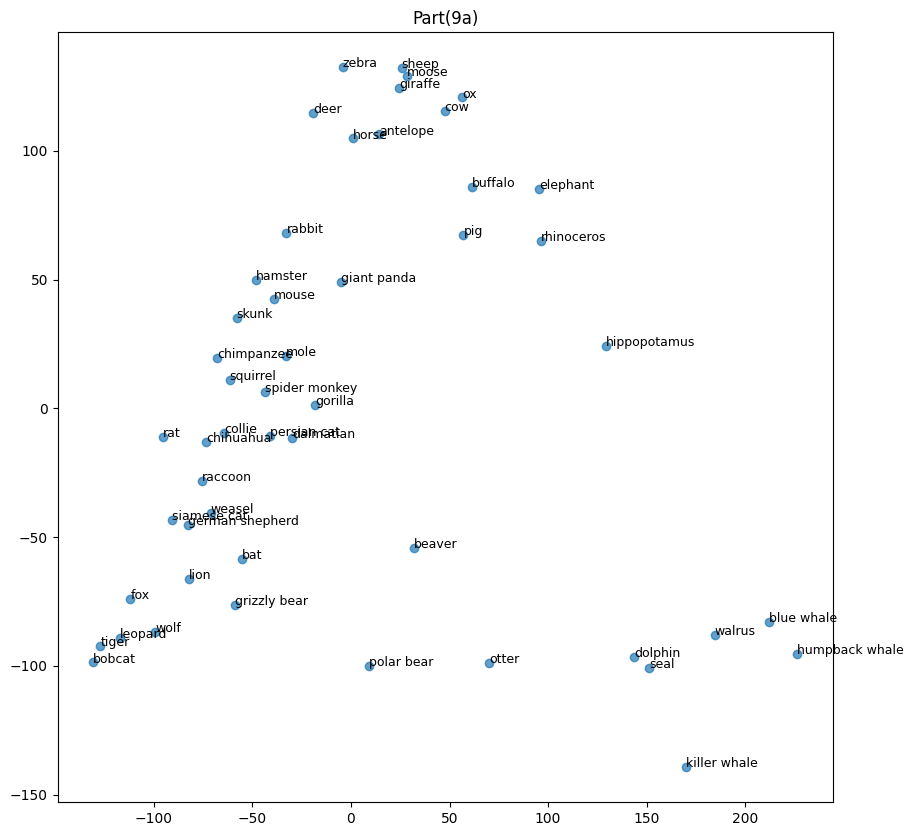

In [58]:
plot_embedding(Z_pa, "Part(9a)")

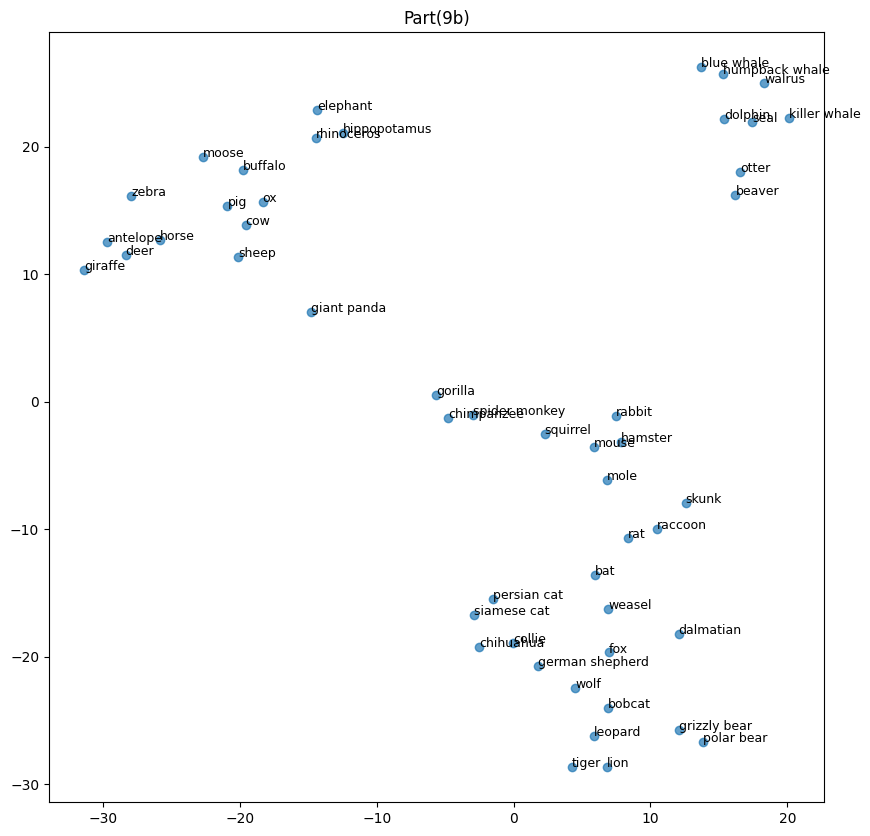

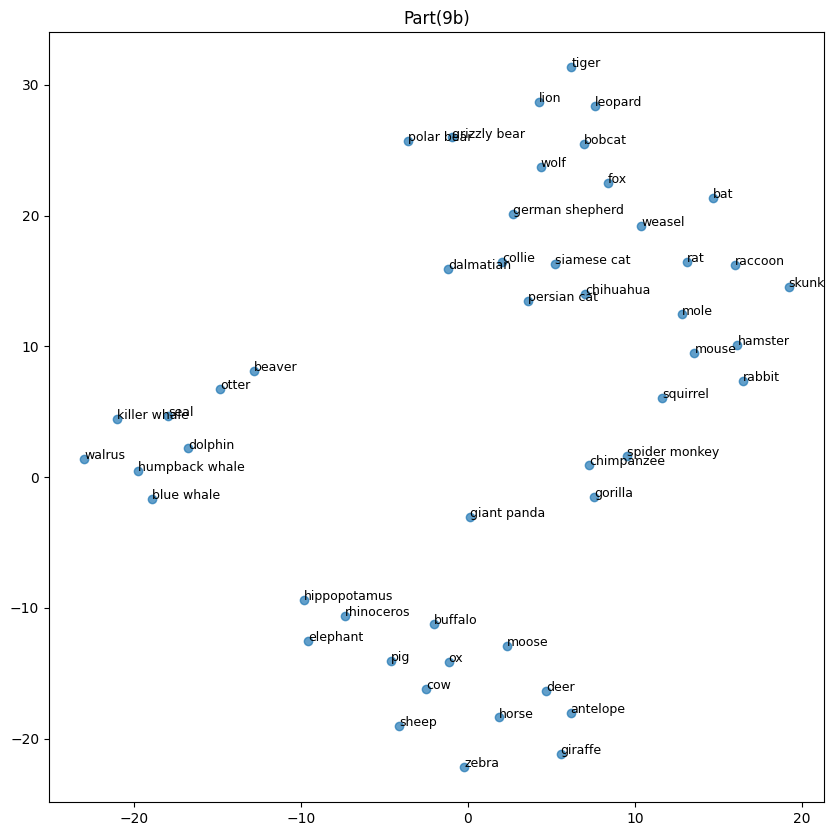

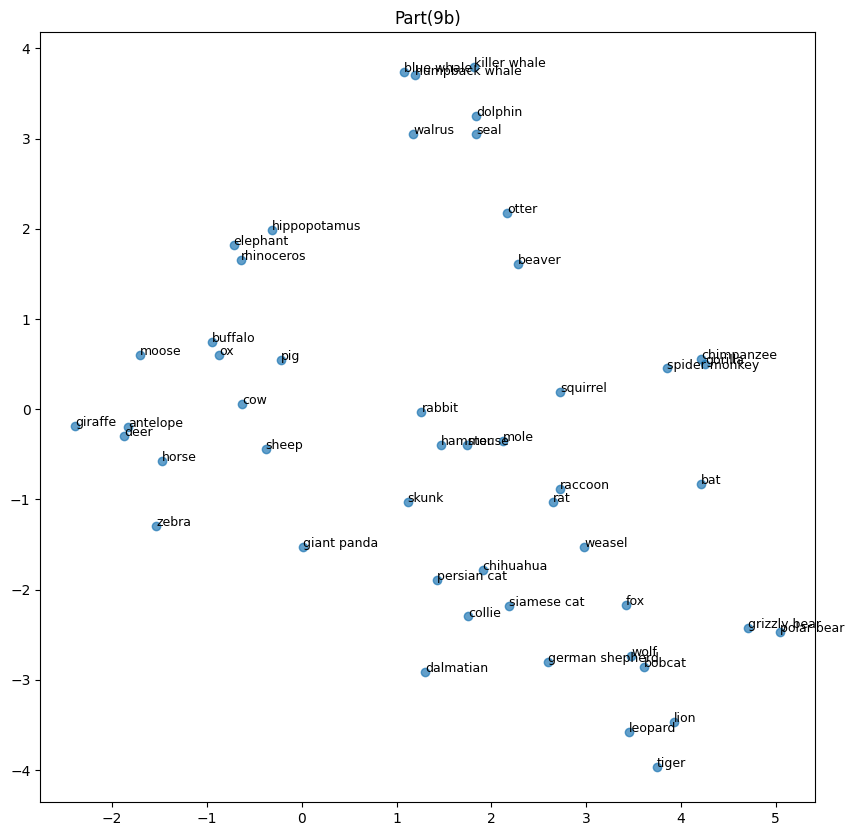

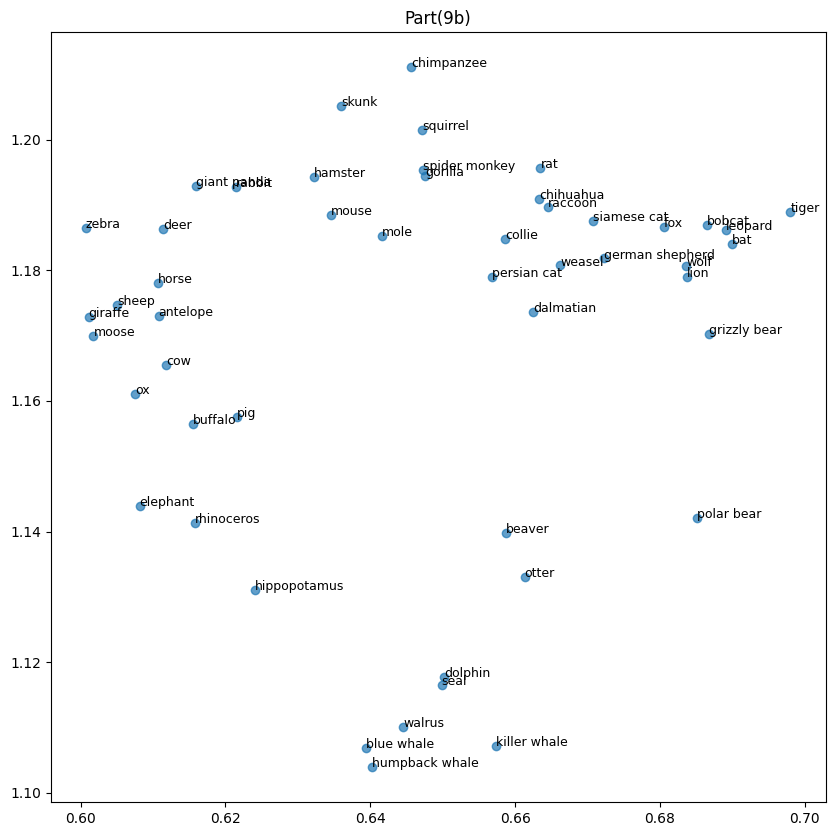

In [59]:
from sklearn.manifold import TSNE
embeds = {'PCA': Z_pa}

for p in [5, 10, 25, 49]:
    Z = TSNE(n_components=2, perplexity=p, random_state=0).fit_transform(X)
    plot_embedding(Z, "Part(9b)")
    embeds[f't-SNE (perplexity={p})'] = Z

In [61]:
for k,Z in embeds.items():
    print(f"K:{k}")
    print(f"Z:{Z}")

K:PCA
Z:[[  14.33200256  106.35992505]
 [ -58.9630861   -76.22681969]
 [ 170.08767172 -139.3662367 ]
 [  31.85582565  -54.04638157]
 [ -29.65753503  -11.3917049 ]
 [ -40.87859041  -10.72272289]
 [   1.17791115  104.79228138]
 [ -82.43016284  -45.38757524]
 [ 211.92608739  -82.83737143]
 [ -90.92835147  -43.3052917 ]
 [ -58.01597662   35.20297112]
 [ -33.18440666   20.17533047]
 [-127.19955243  -92.38136512]
 [ 129.48931695   24.05695316]
 [-117.35250987  -89.2965802 ]
 [  28.55636713  129.17123958]
 [ -43.49964663    6.27693742]
 [ 226.54893728  -95.28906181]
 [  95.64111855   85.05034027]
 [ -18.3316707     1.34492612]
 [  56.58550468  120.70785352]
 [-111.97091878  -74.12827031]
 [  25.79398483  132.31759287]
 [ 151.36316459 -100.93057781]
 [ -67.92677834   19.55128584]
 [ -48.25033667   49.77147826]
 [ -61.48822496   11.07402232]
 [  96.32422934   65.00899433]
 [ -32.71055049   68.2626778 ]
 [ -55.32175189  -58.45553839]
 [  24.47458869  124.27963392]
 [ -99.3303442   -86.88931727]


In [64]:
l = embeds.keys()

PCA                       1.8313
t-SNE (perplexity=5)      1.8761
t-SNE (perplexity=10)     1.6519
t-SNE (perplexity=25)     1.5908
t-SNE (perplexity=49)     1.7277
Best: t-SNE (perplexity=25)


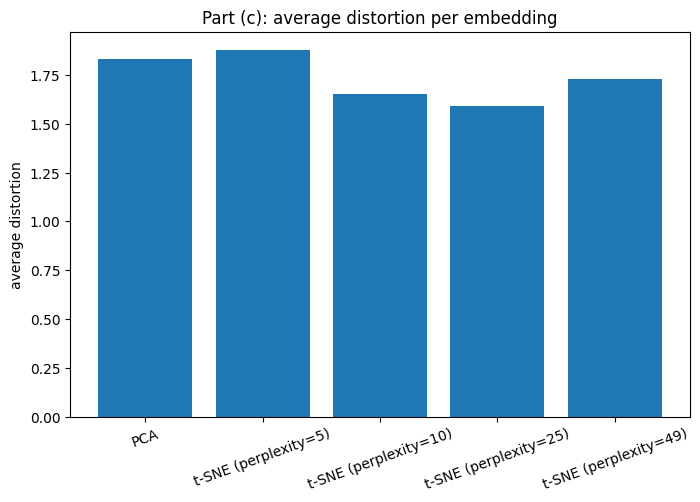

In [65]:
from scipy.spatial.distance import pdist, squareform
def avg_distortion(X, Z):
    D, Dh = squareform(pdist(X)), squareform(pdist(Z))
    c = D.mean()/Dh.mean()
    mask = ~np.eye(len(X), dtype=bool)   # diagonal is 0/0; exclude it
    r = D[mask]/(c*Dh[mask])
    return np.maximum(r, 1/r).mean()

res = {k: avg_distortion(X,Z) for k,Z in embeds.items()}
for k,v in res.items(): print(f'{k:25s} {v:.4f}')
best = min(res, key=res.get); print('Best:', best)
plt.figure(figsize=(8,5)); plt.bar(range(len(res)), list(res.values()))
plt.xticks(range(len(res)), list(res), rotation=20); plt.ylabel('average distortion')
plt.title('Part (c): average distortion per embedding')
plt.savefig('3c_distortion.png', dpi=150, bbox_inches='tight'); plt.show()